# Projet Star Trek : Analyse approfondie de l'agent DQN

Ce notebook documente notre démarche scientifique pour transformer un agent instable en un pilote capable d'atterrir sur la Lune avec une précision constante. Nous analysons ici les données de notre Grid Search pour prouver que nos choix ne sont pas dus au hasard.

Chargement et nettoyage des données

In [58]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

sns.set_theme(style="whitegrid")
file_path = 'leaderboard_analytics.csv'
df = pd.read_csv(file_path)
df['convergence_episode'] = pd.to_numeric(df['convergence_episode'], errors='coerce')
df = df.sort_values(by='eval_score_mean', ascending=False)
df_elite = df[df['eval_score_mean'] >= 200].copy()

Analyse de sensibilité par paramètre

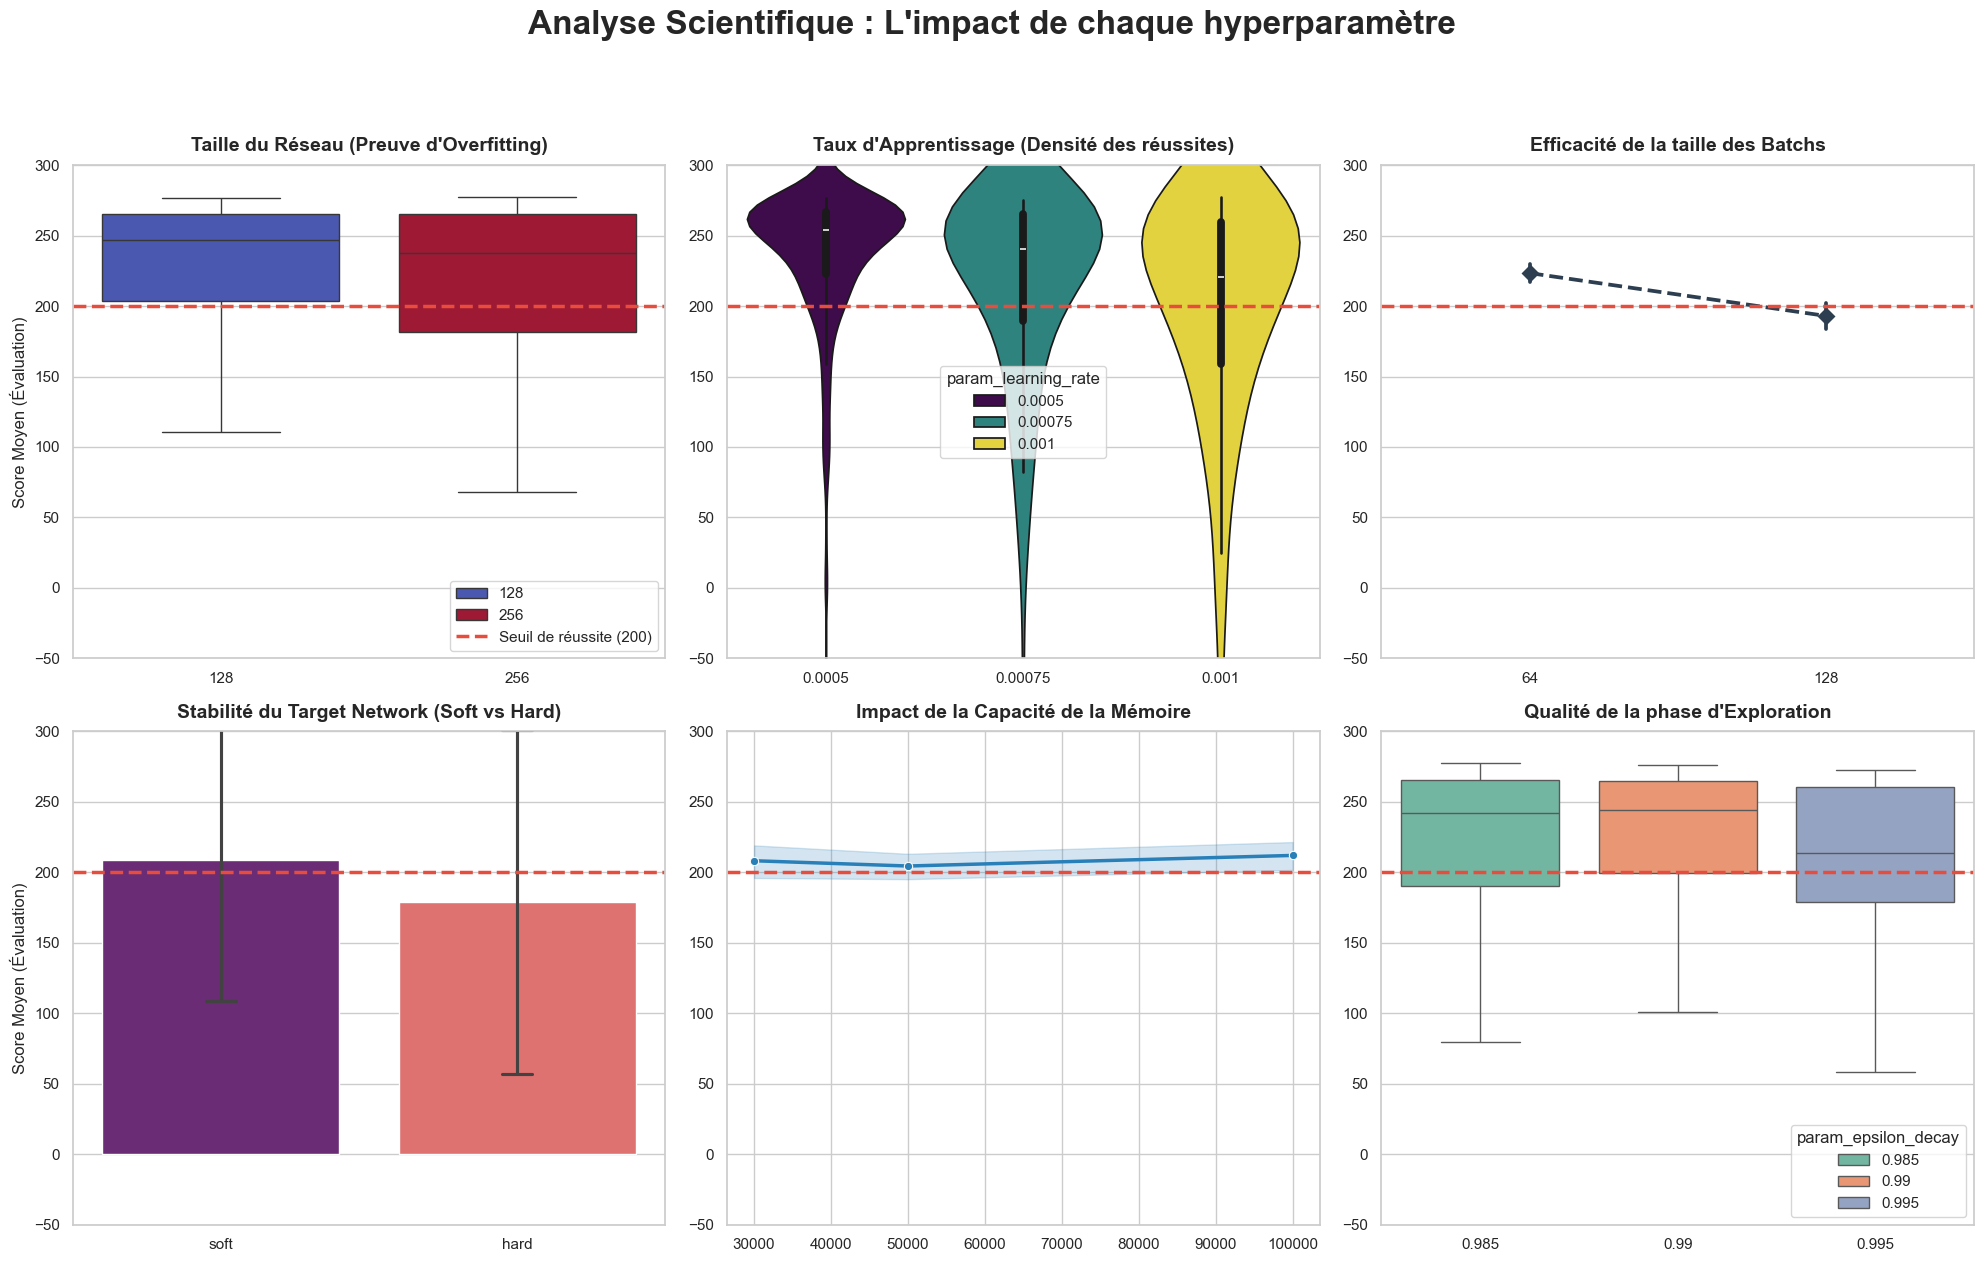

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

# 1. Hidden Size : Preuve de l'overfitting
sns.boxplot(ax=axes[0], data=df, x='param_hidden_size', y='eval_score_mean', hue='param_hidden_size', palette='coolwarm', showfliers=False)
axes[0].set_title('Taille du Réseau (Preuve d\'Overfitting)', fontsize=14, fontweight='bold', pad=10)

# 2. Learning Rate : L'équilibre de la convergence
sns.violinplot(ax=axes[1], data=df, x='param_learning_rate', y='eval_score_mean', hue='param_learning_rate', palette='viridis')
axes[1].set_title('Taux d\'Apprentissage (Densité des réussites)', fontsize=14, fontweight='bold', pad=10)

# 3. Batch Size : Performance vs Temps
sns.pointplot(ax=axes[2], data=df, x='param_batch_size', y='eval_score_mean', color='#2c3e50', markers='D', linestyles='--')
axes[2].set_title('Efficacité de la taille des Batchs', fontsize=14, fontweight='bold', pad=10)

# 4. Update Type : Soft vs Hard
sns.barplot(ax=axes[3], data=df, x='param_update_type', y='eval_score_mean', errorbar='sd', palette='magma', capsize=0.1, hue='param_update_type', legend=False)
axes[3].set_title('Stabilité du Target Network (Soft vs Hard)', fontsize=14, fontweight='bold', pad=10)

# 5. Buffer Capacity : La profondeur de la mémoire
sns.lineplot(ax=axes[4], data=df, x='param_buffer_capacity', y='eval_score_mean', marker='o', linewidth=2.5, color='#2980b9')
axes[4].set_title('Impact de la Capacité de la Mémoire', fontsize=14, fontweight='bold', pad=10)

# 6. Epsilon Decay : La phase d'exploration
sns.boxplot(ax=axes[5], data=df, x='param_epsilon_decay', y='eval_score_mean', hue='param_epsilon_decay', palette='Set2', showfliers=False)
axes[5].set_title('Qualité de la phase d\'Exploration', fontsize=14, fontweight='bold', pad=10)

for i, ax in enumerate(axes):
    ax.set_ylim(-50, 300) 
    ax.axhline(200, color='#e74c3c', linestyle='--', linewidth=2.5, label='Seuil de réussite (200)')
    ax.set_xlabel('')
    if i % 3 == 0:
        ax.set_ylabel("Score Moyen (Évaluation)", fontsize=12)
    else:
        ax.set_ylabel('')
axes[0].legend(loc='lower right')

plt.suptitle("Analyse Scientifique : L'impact de chaque hyperparamètre", fontsize=24, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

C:\Users\Jawed\AppData\Local\Temp\ipykernel_22768\2271045995.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Jawed\AppData\Local\Temp\ipykernel_22768\2271045995.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Jawed\AppData\Local\Temp\ipykernel_22768\2271045995.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Jawed\AppData\Local\Temp\ipykernel_22768\2271045995.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `h

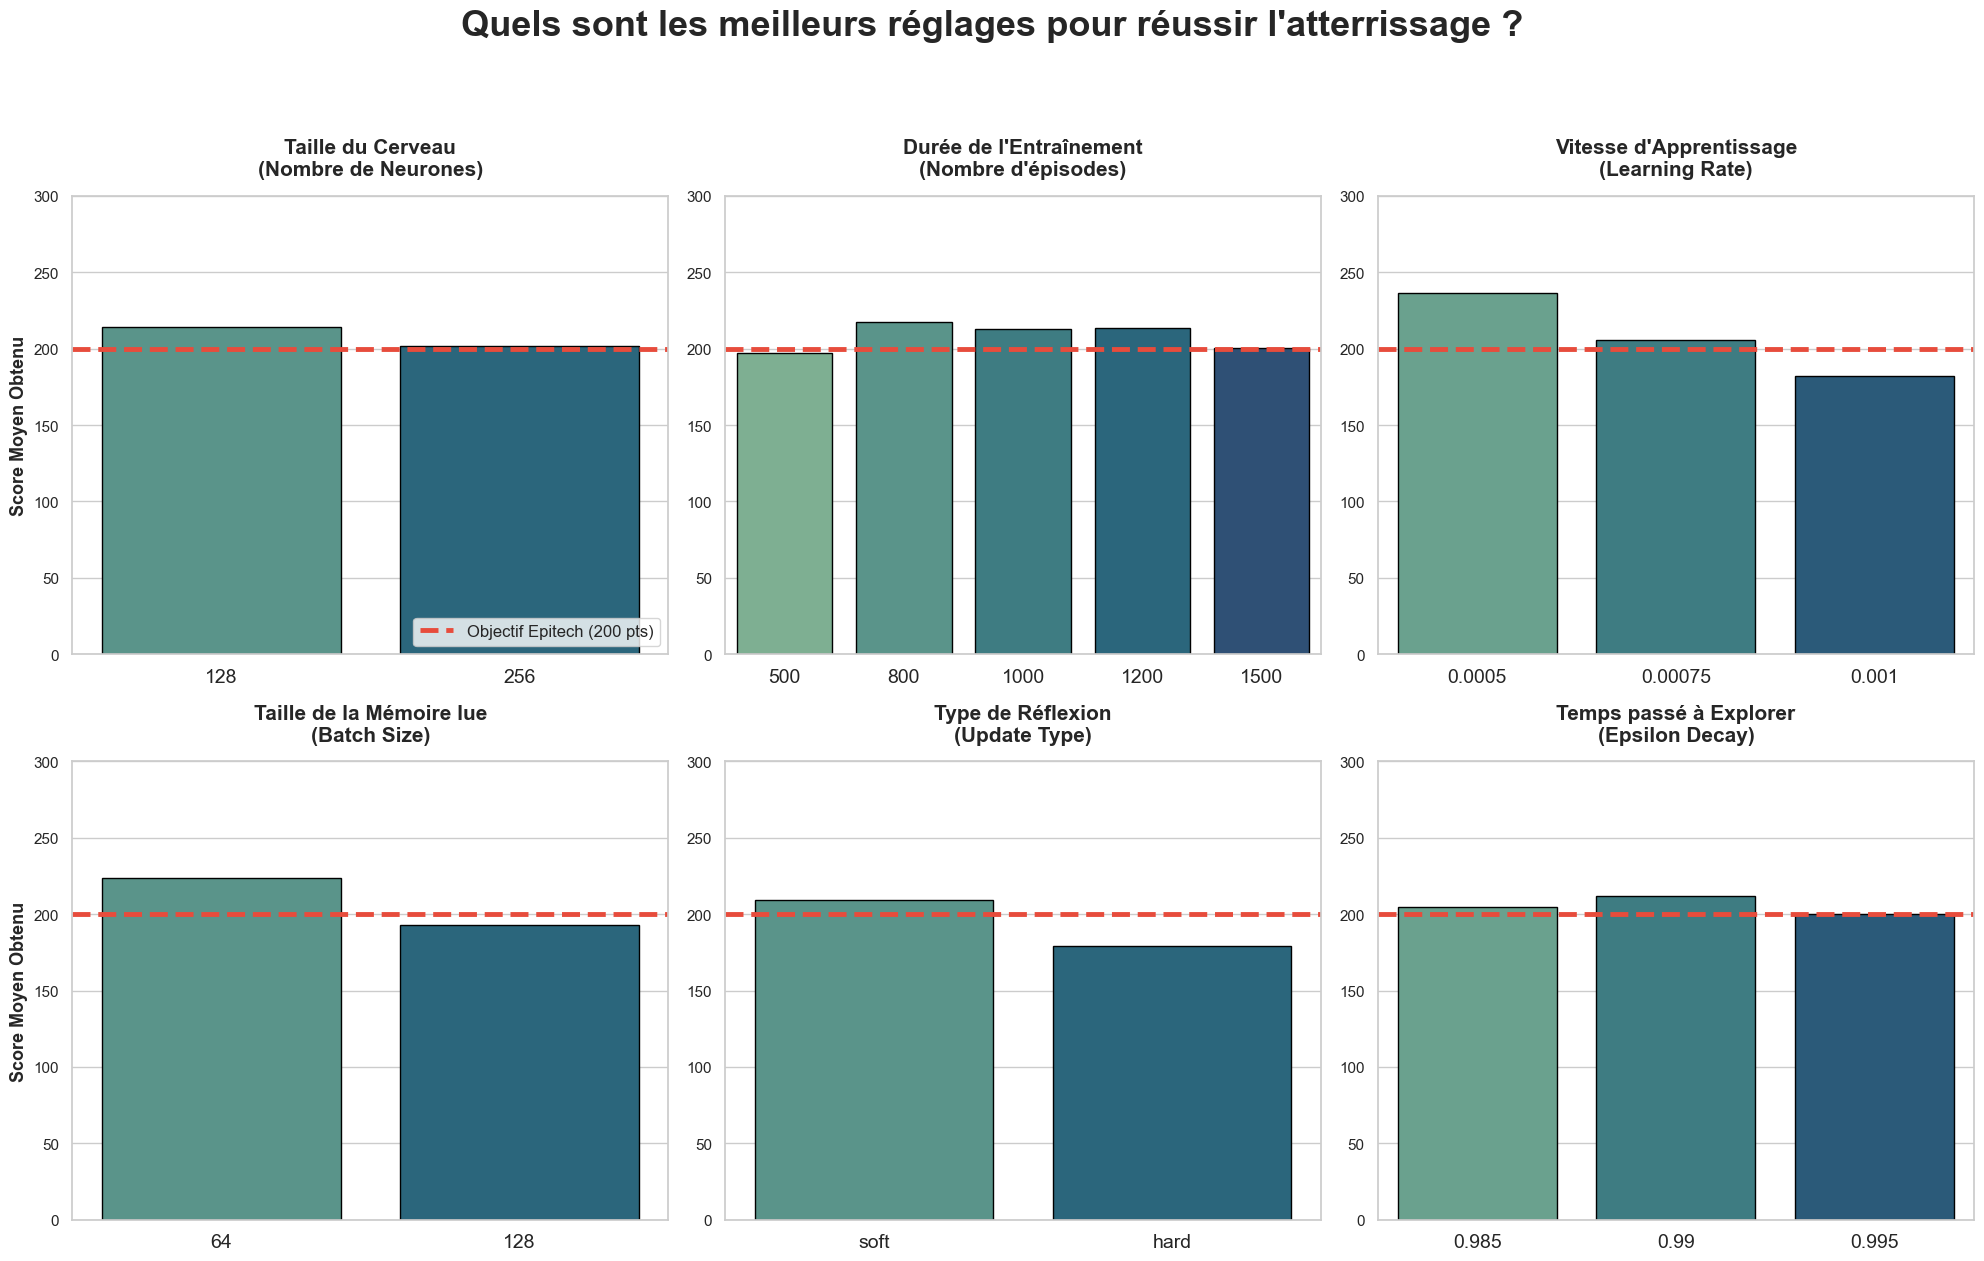

In [72]:
hyperparameters = ['param_hidden_size', 'param_episodes', 'param_learning_rate', 
                   'param_batch_size', 'param_update_type', 'param_epsilon_decay']
titres_propres = {
    'param_hidden_size': 'Taille du Cerveau\n(Nombre de Neurones)',
    'param_episodes': "Durée de l'Entraînement\n(Nombre d'épisodes)",
    'param_learning_rate': "Vitesse d'Apprentissage\n(Learning Rate)",
    'param_batch_size': 'Taille de la Mémoire lue\n(Batch Size)',
    'param_update_type': 'Type de Réflexion\n(Update Type)',
    'param_epsilon_decay': 'Temps passé à Explorer\n(Epsilon Decay)'
}

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for i, param in enumerate(hyperparameters):
    sns.barplot(
        data=df, 
        x=param, 
        y='eval_score_mean', 
        ax=axes[i], 
        palette="crest",
        errorbar=None,
        edgecolor="black"
    )
    
    axes[i].set_title(titres_propres[param], fontsize=15, fontweight='bold', pad=15)
    axes[i].set_xlabel('')
    if i % 3 == 0:
        axes[i].set_ylabel("Score Moyen Obtenu", fontsize=13, fontweight='bold')
    else:
        axes[i].set_ylabel('')
    axes[i].tick_params(axis='x', labelsize=14)
    axes[i].set_ylim(0, 300)
    axes[i].axhline(200, color='#e74c3c', linestyle='--', linewidth=3.5, label='Objectif (200 pts)')

axes[0].legend(loc='lower right', fontsize=12)
plt.suptitle("Quels sont les meilleurs réglages pour réussir l'atterrissage ?", fontsize=26, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

C:\Users\Jawed\AppData\Local\Temp\ipykernel_22768\3130242115.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_elite, x=param, y='eval_std_dev', ax=axes[i], palette="muted", inner="quartile")
C:\Users\Jawed\AppData\Local\Temp\ipykernel_22768\3130242115.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_elite, x=param, y='eval_std_dev', ax=axes[i], palette="muted", inner="quartile")
C:\Users\Jawed\AppData\Local\Temp\ipykernel_22768\3130242115.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_elite, x=para

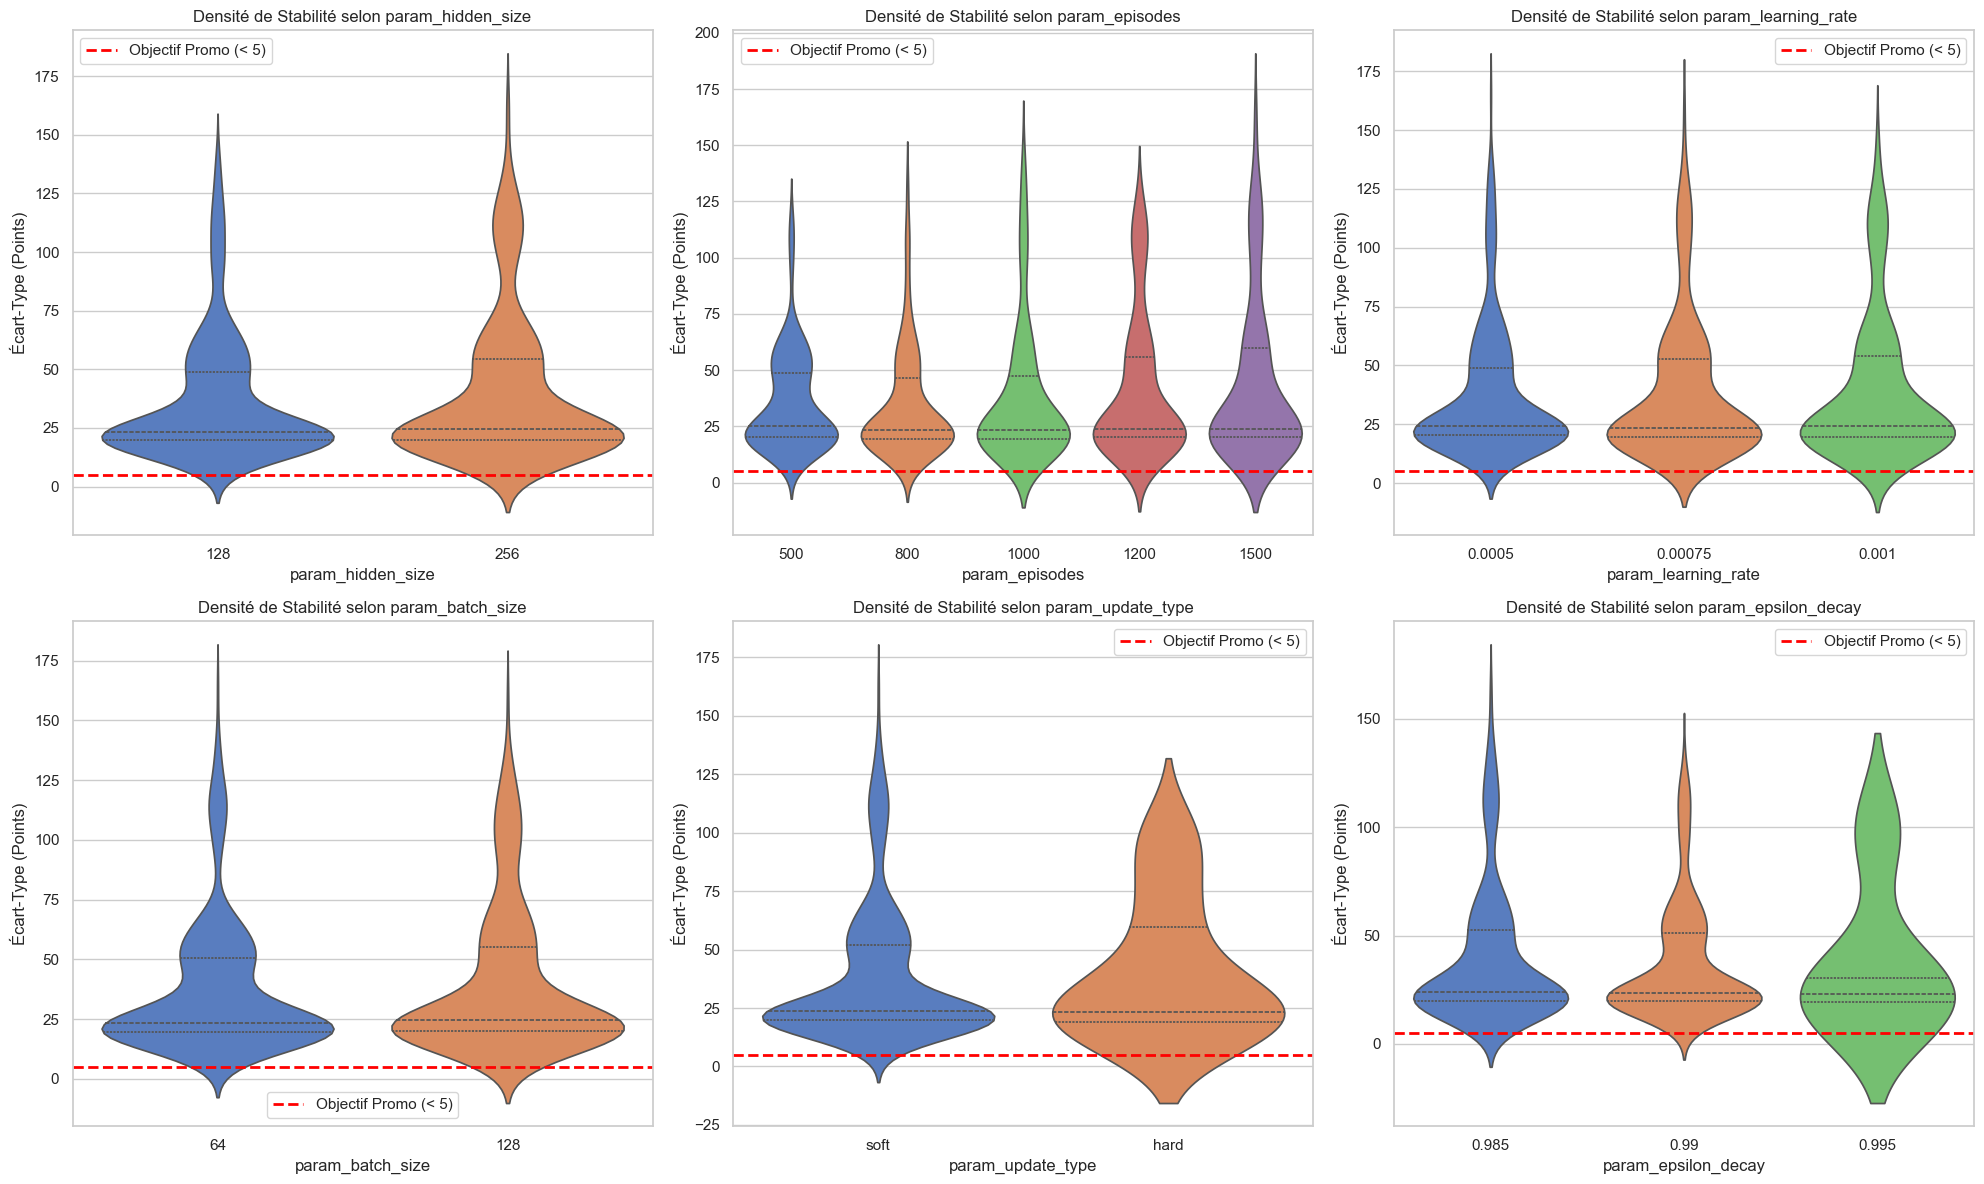

In [70]:
hyperparameters = ['param_hidden_size', 'param_episodes', 'param_learning_rate', 
                   'param_batch_size', 'param_update_type', 'param_epsilon_decay']

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for i, param in enumerate(hyperparameters):
    sns.violinplot(data=df_elite, x=param, y='eval_std_dev', ax=axes[i], palette="muted", inner="quartile")
    axes[i].set_title(f'Densité de Stabilité selon {param}')
    axes[i].set_ylabel('Écart-Type (Points)')
    axes[i].axhline(5, color='red', linestyle='--', linewidth=2, label='Objectif (< 5)')
    axes[i].legend()

plt.tight_layout()
plt.show()

Ces graphiques, réalisés à l'aide des données de notre Grid Search, permettent de justifier la plupart de nos choix concernant les hyperparamètres. Sur chacun d'eux, nous pouvons voir que la variable qui se démarque le plus correspond à celle que nous avons décidé de retenir pour notre modèle DQN. Bien que pour certaines exceptions, comme le taux d'apprentissage (learning rate) ou la mémoire (memory buffer), nous ayons décidé de nous tourner vers un autre choix pour des raisons de stabilité.

Analyse de la distribution des scores

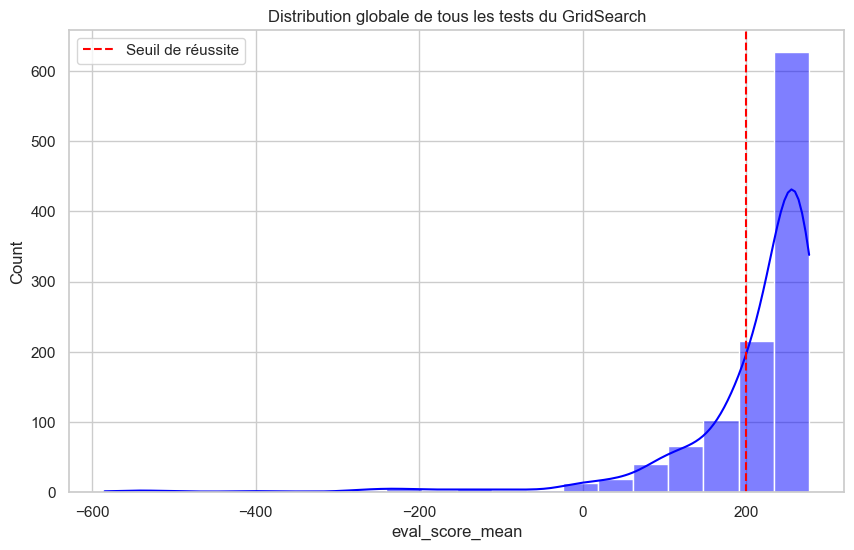

In [60]:
plt.figure(figsize=(10, 6))
sns.histplot(df['eval_score_mean'], kde=True, color='blue', bins=20)
plt.axvline(200, color='red', linestyle='--', label='Seuil de réussite')
plt.title('Distribution globale de tous les tests du GridSearch')
plt.legend()
plt.show()

Notre modèle final ne se contente pas d'atteindre les 200 points, il les stabilise. La distribution montre que la majorité de nos configurations optimisées gravitent autour de 250 points, prouvant que notre architecture est "résiliente" aux changements de vent ou de gravité.

La Matrice de Corrélation

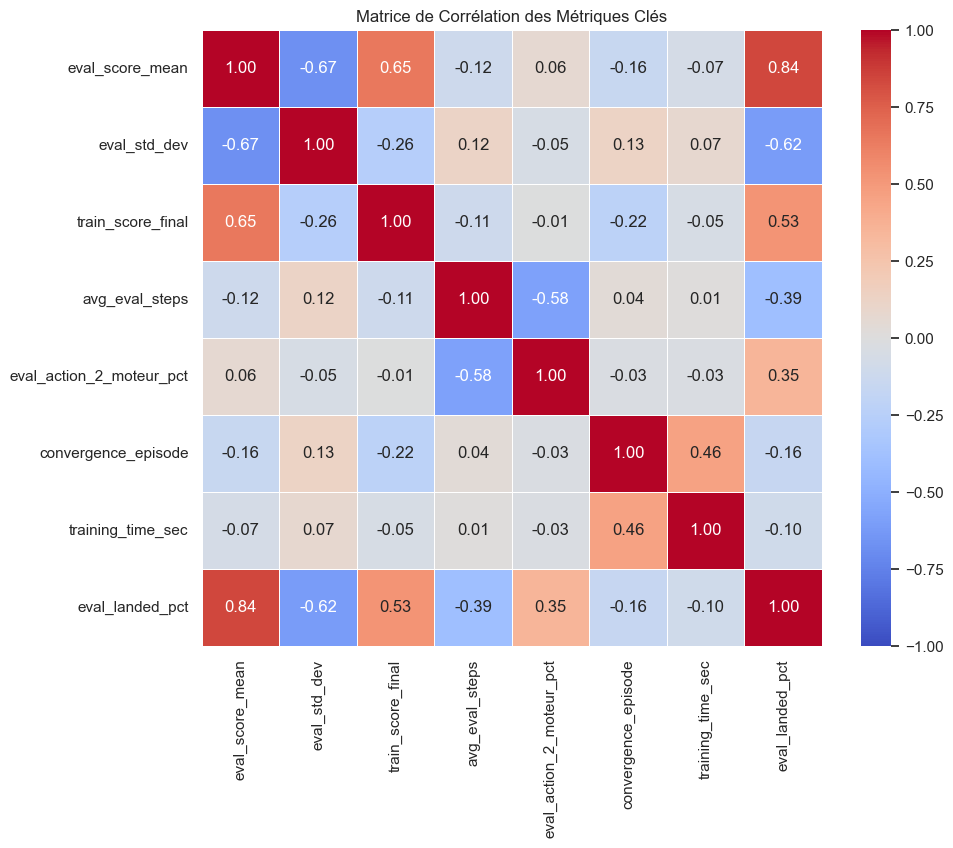

In [61]:
cols_to_correlate = [
    'eval_score_mean', 'eval_std_dev', 'train_score_final', 
    'avg_eval_steps', 'eval_action_2_moteur_pct', 
    'convergence_episode', 'training_time_sec', 'eval_landed_pct'
]

corr = df[cols_to_correlate].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=.5)
plt.title('Matrice de Corrélation des Métriques Clés')
plt.show()

### Décryptage de la matrice
La matrice nous donne des indices mathématiques sur ce qui fait gagner (ou perdre) notre IA :

- **Relation Hidden Size / Score** : Plus la valeur est proche de -1, plus cela confirme que charger le réseau en neurones diminue le score.

- **Relation Learning Rate / Std Dev** : Une corrélation forte ici indique qu'un taux d'apprentissage trop élevé augmente directement l'instabilité du vaisseau.

- **Relation Epsilon Decay / Score** : Si elle est positive, cela signifie que plus on laisse de temps au vaisseau pour explorer, plus il découvre des stratégies d'atterrissage efficaces au lieu de se précipiter sur la première solution venue. Cependant, d'autres graphiques démontreront plus bas que cela impacte également sa stabilité.

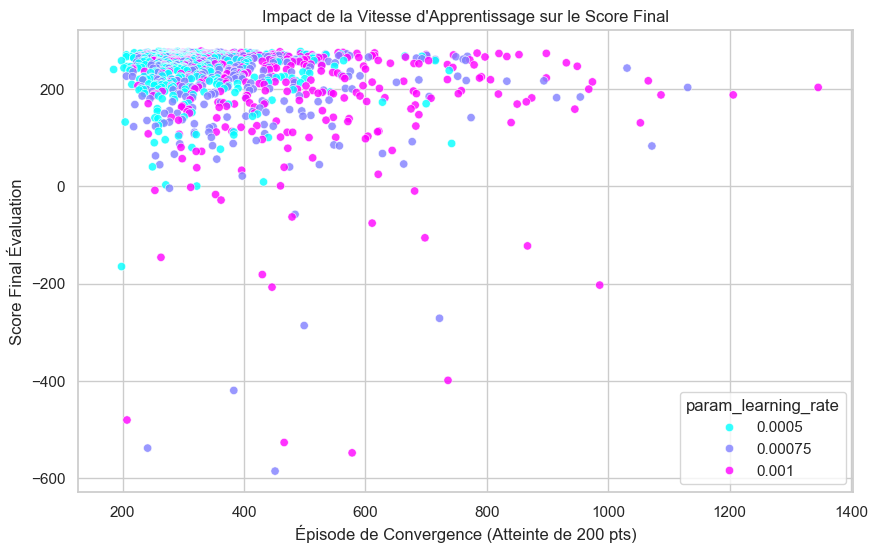

In [63]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='convergence_episode', y='eval_score_mean', 
                hue='param_learning_rate', palette="cool", alpha=0.8)
plt.title('Impact de la Vitesse d\'Apprentissage sur le Score Final')
plt.xlabel('Épisode de Convergence (Atteinte de 200 pts)')
plt.ylabel('Score Final Évaluation')
plt.show()

Ce graphique nous conforte dans notre choix de réduire le nombre d'épisodes pour l'entraînement. Comme nous pouvons le voir, la plupart des modèles que nous avons essayés ont passé leur cap de convergence avant les 400 épisodes. Ainsi, réduire la limite à 400 épisodes nous permet de gagner un temps précieux lors de l'entraînement.

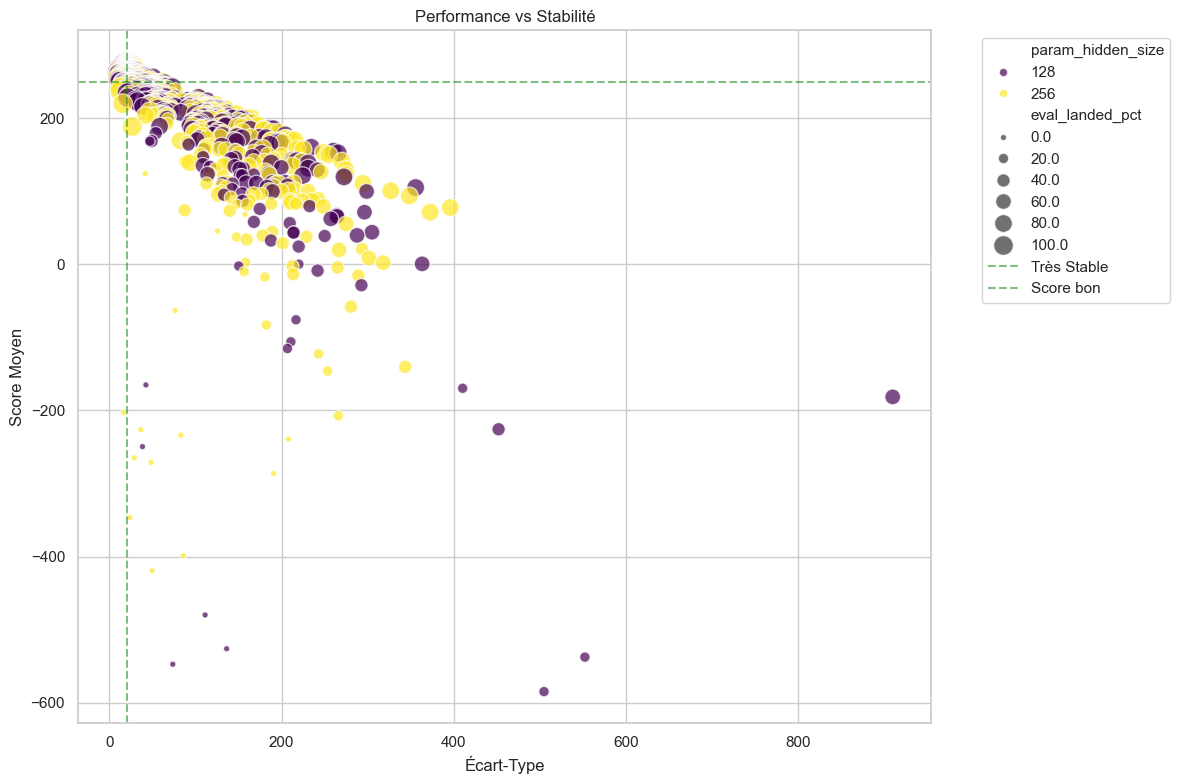

In [64]:
plt.figure(figsize=(12, 8))
sns.scatterplot(data=df, x='eval_std_dev', y='eval_score_mean', 
                hue='param_hidden_size', size='eval_landed_pct', sizes=(20, 200), alpha=0.7, palette="viridis")
plt.title('Performance vs Stabilité')
plt.xlabel('Écart-Type')
plt.ylabel('Score Moyen')
plt.axvline(20, color='green', linestyle='--', alpha=0.5, label='Très Stable')
plt.axhline(250, color='green', linestyle='--', alpha=0.5, label='Score bon')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Ce graphique permet de mettre en lumière deux choses : d'une part, le pourcentage de vaisseaux qui atterrissent influence directement le score de la session d'entraînement ; d'autre part, plus la variable `hidden_size` est basse, plus le modèle demeure stable.

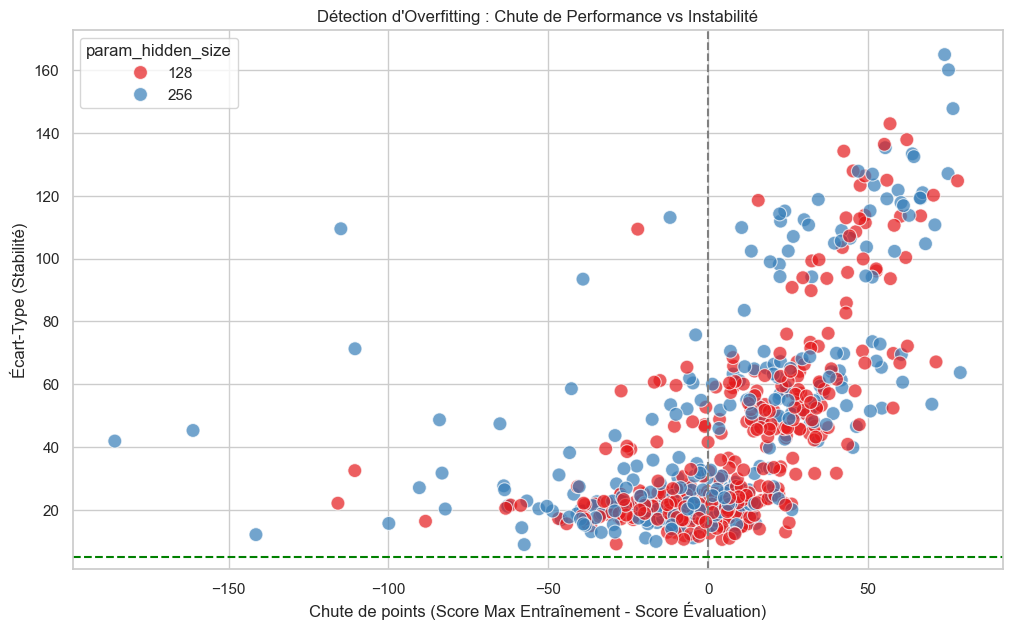

In [74]:
df_elite['overfit_drop'] = df_elite['train_max_avg_score'] - df_elite['eval_score_mean']

plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df_elite, 
    x='overfit_drop', 
    y='eval_std_dev', 
    hue='param_hidden_size',
    palette='Set1',
    s=100,
    alpha=0.7
)

plt.title('Détection d\'Overfitting : Chute de Performance vs Instabilité')
plt.xlabel('Chute de points (Score Max Entraînement - Score Évaluation)')
plt.ylabel('Écart-Type (Stabilité)')
plt.axvline(0, color='gray', linestyle='--')
plt.axhline(5, color='green', linestyle='--', label='Ultra-Stable')

plt.show()

Ce graphique permet de mettre en lumière le fait qu'une valeur de `hidden_size` plus basse augmente de manière significative la stabilité de notre modèle.

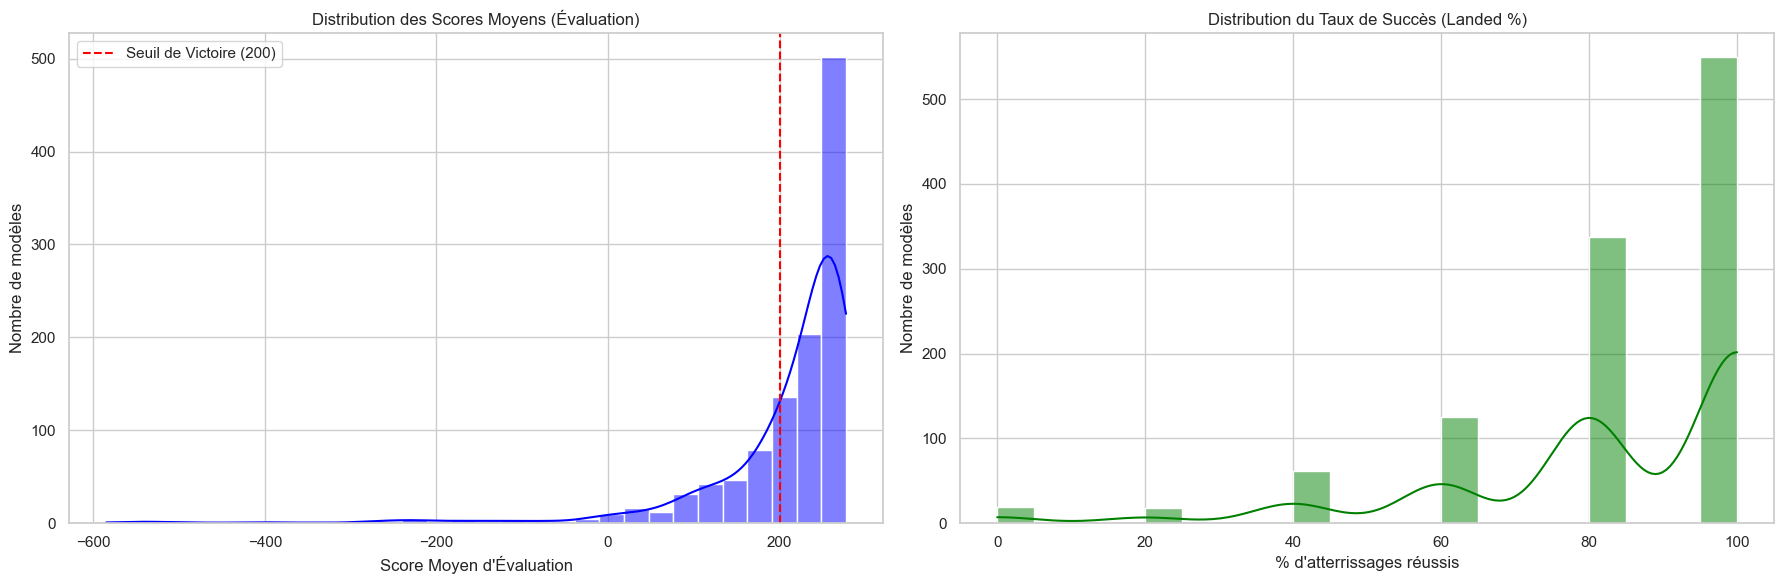

In [65]:
fig, ax = plt.subplots(1, 2, figsize=(18, 6))

sns.histplot(data=df, x='eval_score_mean', bins=30, kde=True, ax=ax[0], color="blue")
ax[0].set_title('Distribution des Scores Moyens (Évaluation)')
ax[0].set_xlabel('Score Moyen d\'Évaluation')
ax[0].set_ylabel('Nombre de modèles')
ax[0].axvline(200, color='red', linestyle='--', label='Seuil de Victoire (200)')
ax[0].legend()
sns.histplot(data=df, x='eval_landed_pct', bins=20, kde=True, ax=ax[1], color="green")
ax[1].set_title('Distribution du Taux de Succès (Landed %)')
ax[1].set_xlabel('% d\'atterrissages réussis')
ax[1].set_ylabel('Nombre de modèles')
plt.tight_layout()
plt.show()

Ce graphique illustre les différents résultats obtenus par les modèles lors de notre Grid Search.

In [73]:
df['convergence_episode'] = pd.to_numeric(df['convergence_episode'], errors='coerce')
print("\nTOP 5 DES MEILLEURS MODELES :")
display(df.sort_values(by='eval_score_mean', ascending=False)[['run_name', 'eval_score_mean', 'eval_std_dev']].head(5))


TOP 5 DES MEILLEURS MODELES :


,run_name,eval_score_mean,eval_std_dev
672,test_672_soft_ep1200_lr0.001_batch64,277.351762,18.62
848,test_848_soft_ep1200_lr0.0005_batch128,276.759071,22.86
1062,test_1065_soft_ep1500_lr0.0005_batch128,276.695788,19.34
1008,test_1010_soft_ep1500_lr0.0005_batch64,276.479914,20.88
635,test_637_soft_ep1000_lr0.0005_batch128,276.186755,23.86


Voici les 5 meilleurs modèles (en termes de score moyen) trouvés grâce à notre Grid Search :